# Masked autoencoder + MLP for LE (US-ARM 2017): daily and daytime

Standalone: downloads only the GitHub folder https://github.com/mich3leRusso/evotranspiration (`autoencoder.py` + the raw `ARM_HH_2017.csv`), installs the missing libraries and runs the functions of `autoencoder.py`.

**0. Preprocessing**: MDS gap-filling of the raw half-hourly data (Reichstein et al., 2005).

**Daily** (one sample = one day, 14 feature-set-2 drivers): pretrain → transfer → latent counterfactuals → SHAP.

**Daytime** (one sample = one daytime half-hour, 8 feature-set-2 drivers): pretrain → transfer → SHAP.

In [1]:
import importlib.util
import io
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# 1. download the GitHub folder (zip of the main branch) and unpack it
ZIP = "https://github.com/mich3leRusso/evotranspiration/archive/refs/heads/main.zip"
with urllib.request.urlopen(ZIP) as r:
    zipfile.ZipFile(io.BytesIO(r.read())).extractall(".")
FOLDER = Path("evotranspiration-main").resolve()
print("downloaded:", sorted(p.name for p in FOLDER.iterdir()))

# 2. install the libraries that are missing
for module, package in {"torch": "torch", "shap": "shap", "xgboost": "xgboost", "sklearn": "scikit-learn"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 3. import the functions from the downloaded autoencoder.py
sys.path.insert(0, str(FOLDER))
import torch
from IPython.display import Image, display

from autoencoder import FIG, attack, load, preprocess, pretrain, shapley, transfer

torch.set_num_threads(4)

downloaded: ['ARM_HH_2017.csv', 'autoencoder.py']


.../site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 0. Preprocessing
Raw `ARM_HH_2017.csv` → MDS gap-filling (look-up tables on SW_IN, TA, VPD, then mean diurnal course; RH rebuilt from TA and VPD) → `ARM_HH_2017_filled.csv`, the input of every step below.

In [2]:
filled = preprocess()

Loaded 17520 half-hours x 45 columns, 2017-01-01 00:00:00 -> 2017-12-31 23:30:00
Dropped empty columns (no data to fill from): ['TS_F_MDS_3', 'TS_F_MDS_8']
          WD: filled  193 values (qc1=193, qc2=0, qc3=0)
       USTAR: filled  193 values (qc1=193, qc2=0, qc3=0)
          RH: filled  814 values (qc1=814, qc2=0, qc3=0)
      NETRAD: filled  255 values (qc1=255, qc2=0, qc3=0)
     PPFD_IN: filled  101 values (qc1=101, qc2=0, qc3=0)
    PPFD_OUT: filled  100 values (qc1=100, qc2=0, qc3=0)
      SW_DIF: filled  100 values (qc1=100, qc2=0, qc3=0)
      SW_OUT: filled  102 values (qc1=102, qc2=0, qc3=0)
      LW_OUT: filled  100 values (qc1=100, qc2=0, qc3=0)


gap-filled data -> evotranspiration-main/ARM_HH_2017_filled.csv


# Daily

## Data
One sample = one day: the daily means of the feature-set-2 drivers. Test days = the daily artificial gaps (30 %, Moffat 2007 gap lengths).

In [3]:
daily, feats, stats = load("daily")
print(f"{len(feats)} drivers: {', '.join(feats)}")
print(f"training days {(daily.gap == 0).sum()}, test days {(daily.gap > 0).sum()}")

14 drivers: WS_F, RH, NETRAD, TS_F_MDS_2, TS_F_MDS_6, TS_F_MDS_9, SWC_F_MDS_1, SWC_F_MDS_3, SWC_F_MDS_5, SWC_F_MDS_7, SWC_F_MDS_9, G, H, RECO
training days 255, test days 110


## 1. Pretraining the masked autoencoder
Criteria fixed before training (110 test days): a) mean unmasked R² ≥ 0.90; b) every driver, hidden alone, reconstructed with R² > 0.

             R2_unmasked  R2_masked_alone  R2_linear_from_others
WS_F               0.880            0.298                  0.094
RH                 0.942            0.158                  0.326
NETRAD             0.937            0.808                  0.819
TS_F_MDS_2         0.988            0.982                  0.996
TS_F_MDS_6         0.987            0.981                  0.996
TS_F_MDS_9         0.979            0.966                  0.983
SWC_F_MDS_1        0.899            0.843                  0.905
SWC_F_MDS_3        0.939            0.934                  0.918
SWC_F_MDS_5        0.909            0.583                  0.794
SWC_F_MDS_7        0.875            0.788                  0.895
SWC_F_MDS_9        0.916            0.842                  0.854
G                  0.876            0.520                  0.611
H                  0.736            0.337                  0.443
RECO               0.941            0.733                  0.767 

mean R² unmasked 0.915 

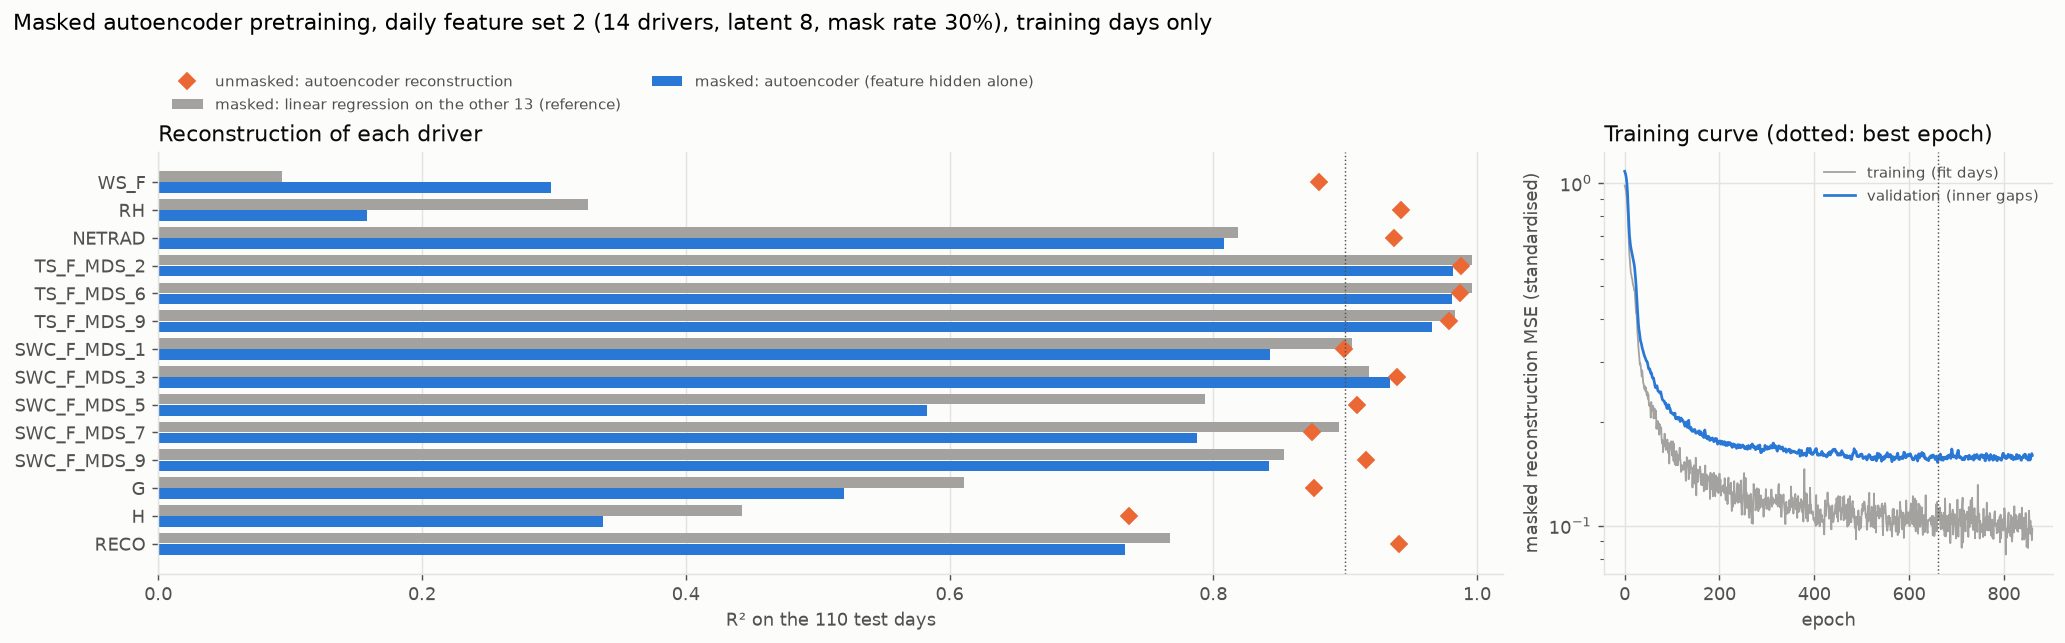

In [4]:
ae, reconstruction = pretrain()
display(Image(FIG / "1_pretrain_reconstruction.png"))

## 2. Transfer learning: frozen encoder + MLP head → daily LE

                model  n_test    R2  RMSE   MAE   bias
    autoencoder + MLP     110 0.906 1.270 0.985 -0.131
   MLP on raw drivers     110 0.964 0.784 0.597  0.051
XGBoost feature set 2     110 0.920 1.169 0.866 -0.305


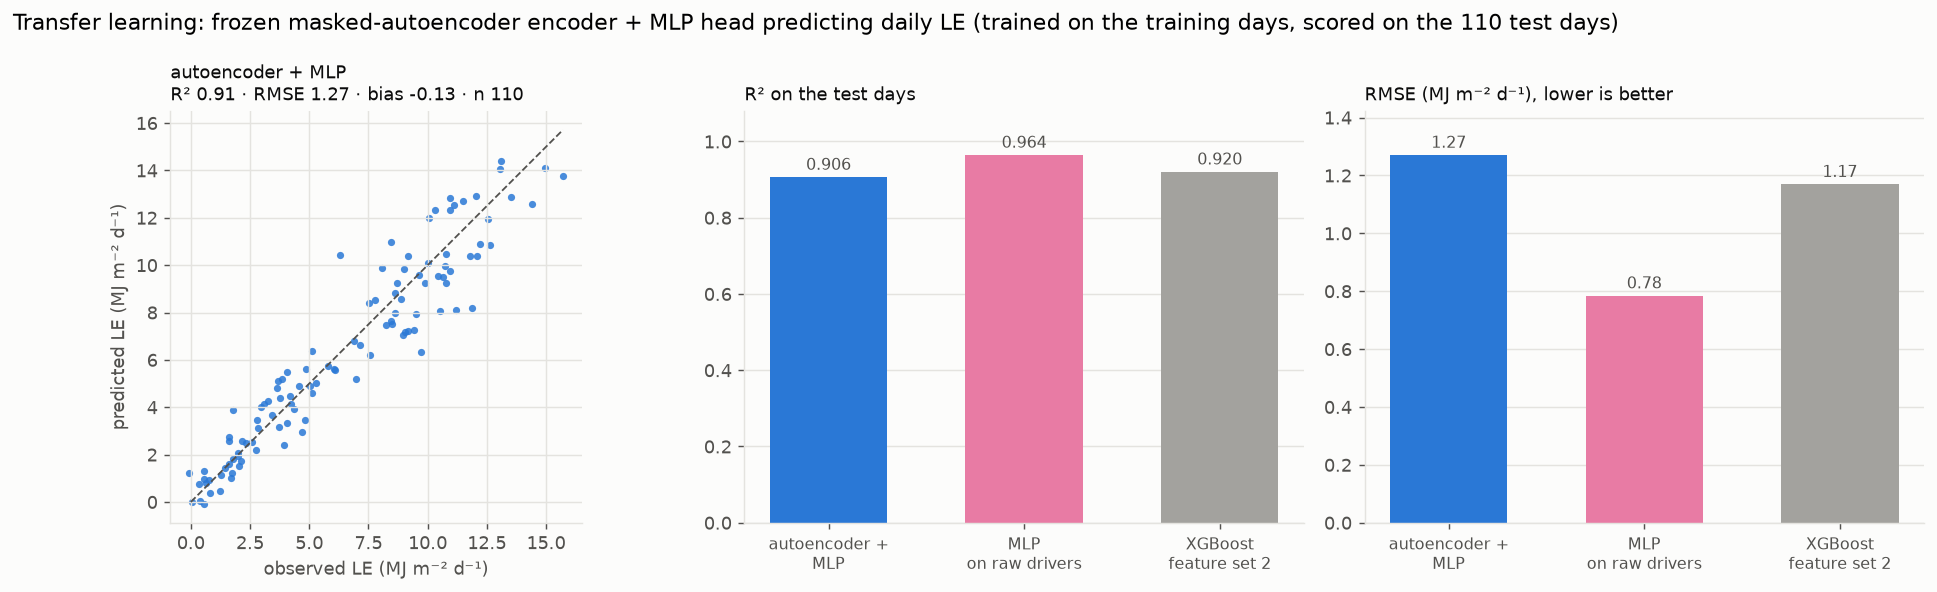

In [5]:
transfer_scores = transfer()
display(Image(FIG / "2_transfer_learning.png"))

## 3. Latent counterfactuals
Orange: the model is pushed to predict more ET (+3 MJ m⁻² d⁻¹). Blue: pushed to predict less ET (−3 MJ m⁻² d⁻¹). Bars = mean change of each decoded driver, as a fraction of its observed range; drivers ranked by bar length.

           days  reached  out_of_range  median_steps  median_delta_norm
direction                                                              
down        246      246            29          54.5             1.4333
up          365      365           115          56.0             1.4739 

mean change of each decoded driver (fraction of its observed range)
 direction      down               up         
               mean mean_abs    mean mean_abs
G           -0.0157   0.0798  0.0295   0.1067
H           -0.0400   0.0885  0.0481   0.0929
NETRAD      -0.1690   0.1693  0.1950   0.1956
RECO        -0.0789   0.0850  0.0956   0.1015
RH           0.0387   0.1029 -0.0080   0.1010
SWC_F_MDS_1 -0.0624   0.0715  0.0824   0.0923
SWC_F_MDS_3 -0.0646   0.0830  0.0659   0.0962
SWC_F_MDS_5 -0.0367   0.0568  0.0440   0.0676
SWC_F_MDS_7 -0.0643   0.0818  0.0906   0.1000
SWC_F_MDS_9 -0.0201   0.0699  0.0599   0.0877
TS_F_MDS_2  -0.0254   0.0600  0.0490   0.0682
TS_F_MDS_6  -0.0432   0.0627  0.0696   0.07

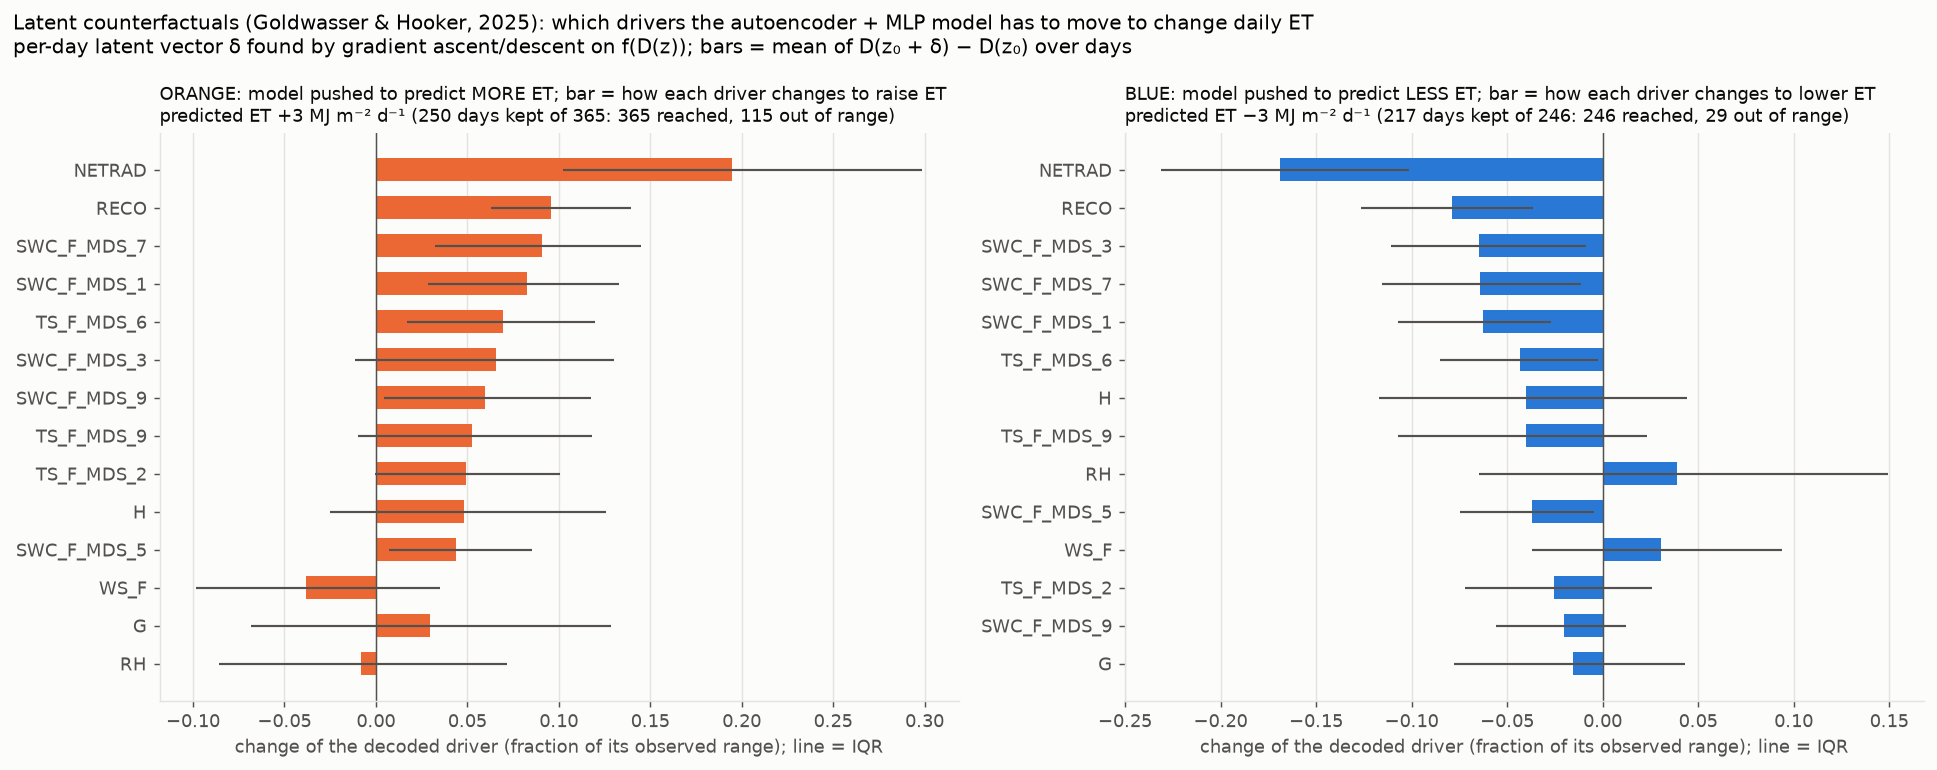

In [6]:
per_day, sensitivity = attack()
display(Image(FIG / "3_latent_counterfactuals.png"))

## 4. SHAP values
`shap.ExactExplainer` on the full model (encoder + MLP) with the 14 drivers as inputs; background = the 255 training days.

daily: base value (mean prediction on the background) 4.662 MJ m⁻² d⁻¹; max |sum(phi) + base - f(x)| = 9.5e-07

mean |SHAP| (MJ m⁻² d⁻¹)
 RECO           1.1140
NETRAD         1.0422
SWC_F_MDS_1    0.6263
SWC_F_MDS_5    0.5459
TS_F_MDS_6     0.4793
RH             0.4202
SWC_F_MDS_7    0.3865
TS_F_MDS_2     0.3158
SWC_F_MDS_3    0.2913
G              0.2095
H              0.1525
WS_F           0.1328
SWC_F_MDS_9    0.1228
TS_F_MDS_9     0.1136


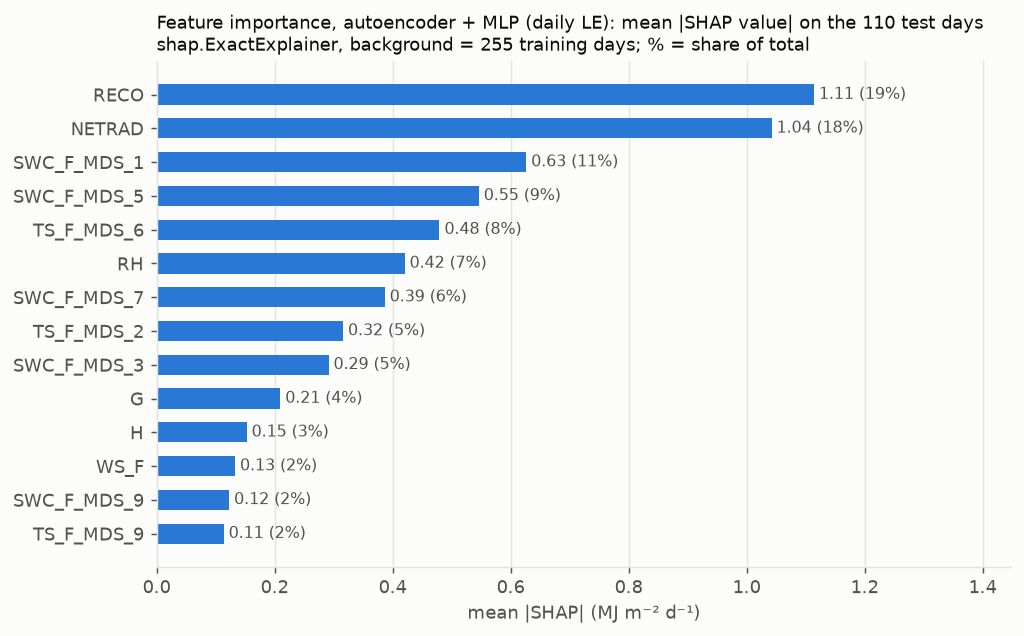

In [7]:
shap_values, shap_importance = shapley()
display(Image(FIG / "5_shap_importance.png"))

# Daytime
Same architecture and settings on the half-hourly daytime data (NIGHT == 0), with the daytime feature set 2 and the half-hourly artificial gaps.

In [8]:
day, day_feats, _ = load("daytime")
print(f"{len(day_feats)} drivers: {', '.join(day_feats)}")
print(f"training half-hours {(day.gap == 0).sum()}, test half-hours {(day.gap > 0).sum()}")

8 drivers: NETRAD, CO2_F_MDS, TS_F_MDS_1, TS_F_MDS_6, SWC_F_MDS_1, SWC_F_MDS_9, H, RECO
training half-hours 6410, test half-hours 2744


## 1. Pretraining (daytime)

             R2_unmasked  R2_masked_alone  R2_linear_from_others
NETRAD             0.981            0.753                  0.665
CO2_F_MDS          0.980            0.418                  0.290
TS_F_MDS_1         0.983            0.899                  0.870
TS_F_MDS_6         0.976            0.919                  0.899
SWC_F_MDS_1        0.956            0.801                  0.635
SWC_F_MDS_9        0.923            0.797                  0.532
H                  0.983            0.772                  0.684
RECO               0.960            0.448                  0.429 

mean R² unmasked 0.968 (criterion a: >= 0.9 -> PASS)
masked alone > 0 for every feature (criterion b) -> PASS


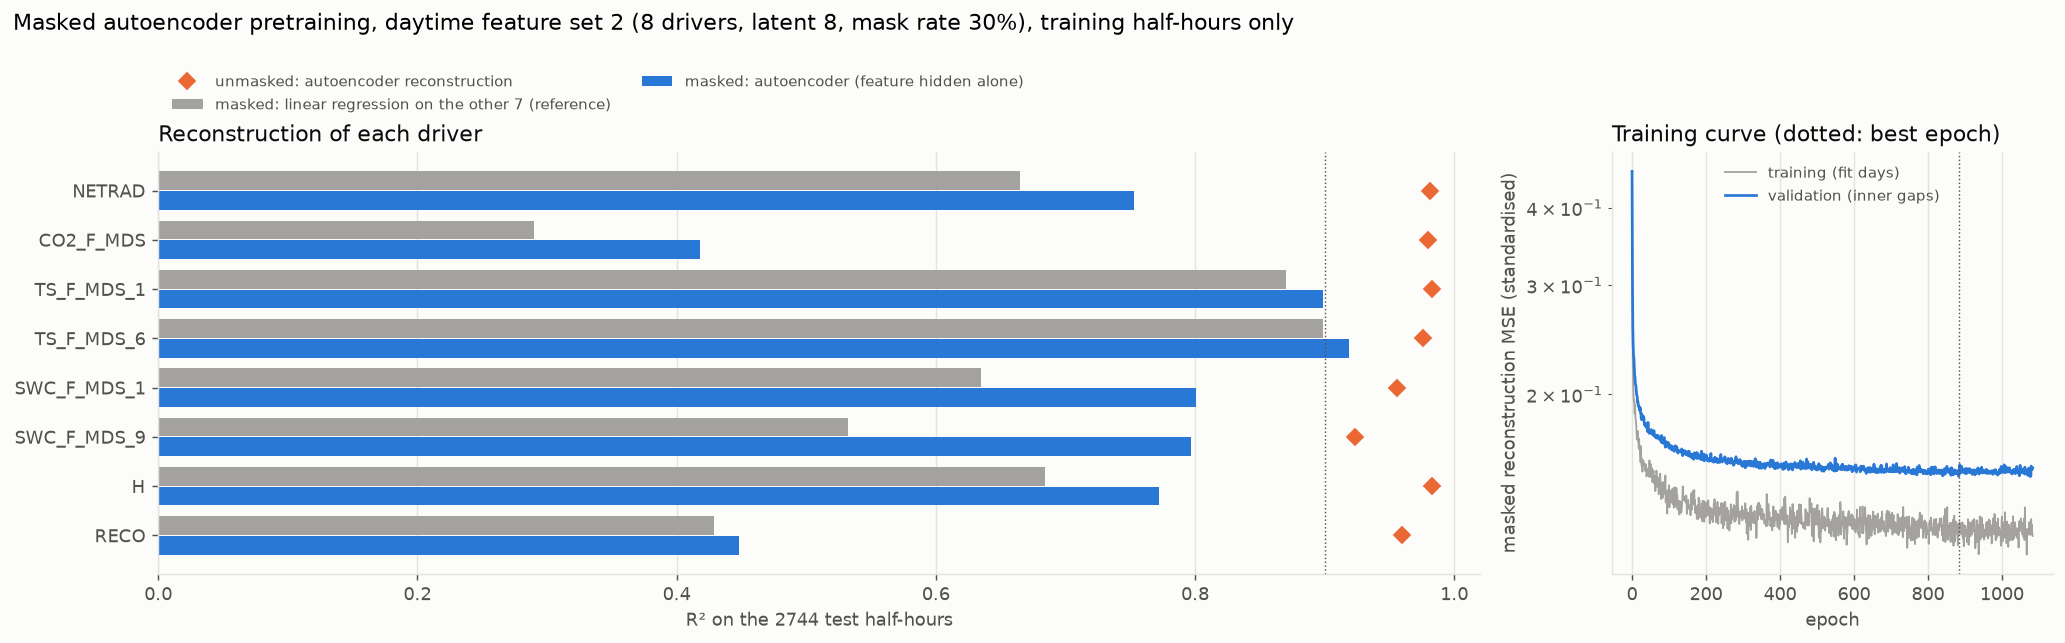

In [9]:
ae_day, reconstruction_day = pretrain("daytime")
display(Image(FIG / "1_pretrain_reconstruction_daytime.png"))

## 2. Transfer learning (daytime)

                model  n_test    R2   RMSE    MAE   bias
    autoencoder + MLP    2744 0.909 31.837 22.748 -2.080
   MLP on raw drivers    2744 0.916 30.572 21.977  0.658
XGBoost feature set 2    2744 0.935 26.993 18.914  0.588


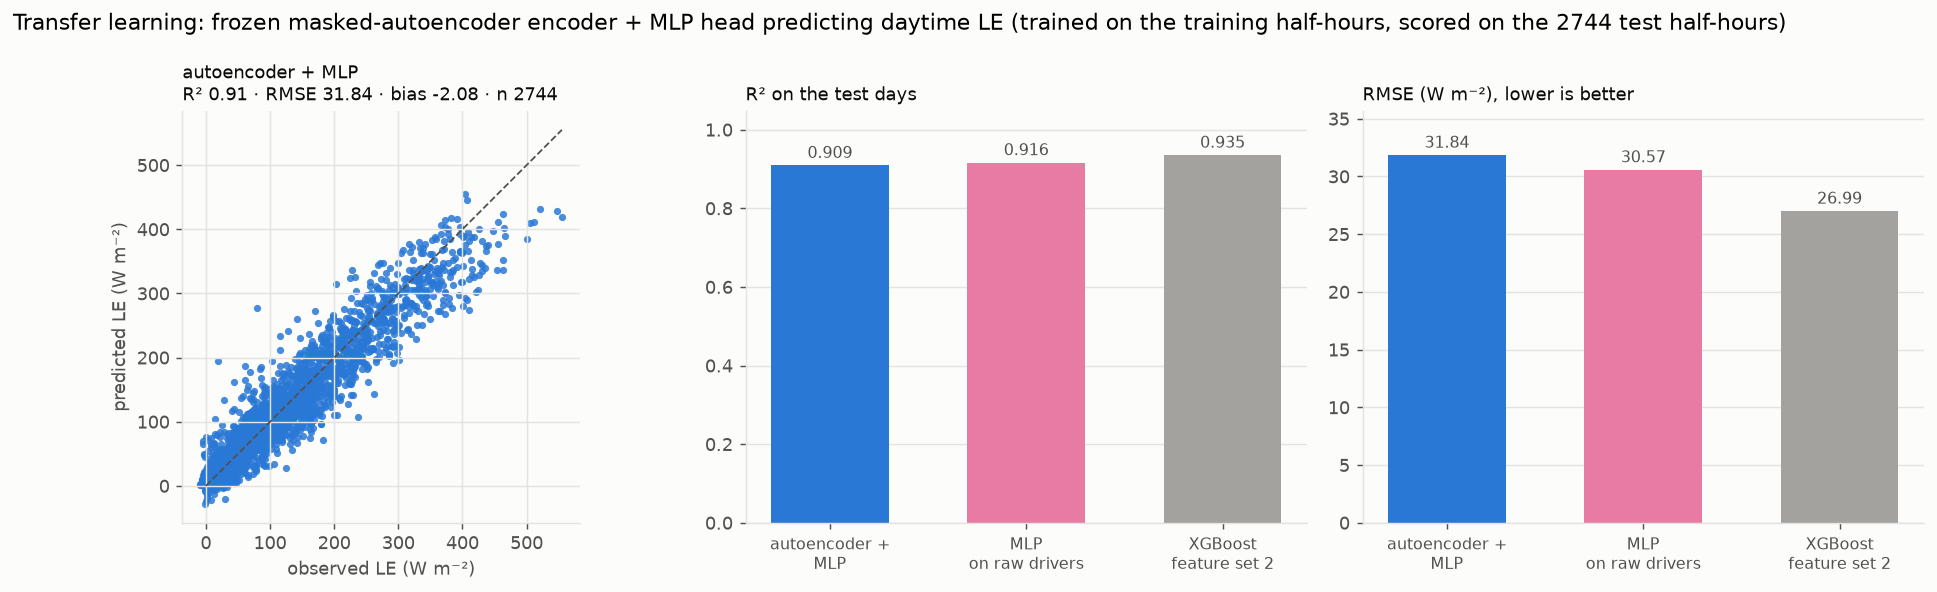

In [10]:
transfer_scores_day = transfer("daytime")
display(Image(FIG / "2_transfer_learning_daytime.png"))

## 4. SHAP values (daytime)
`shap.ExactExplainer`; background = 100 training half-hours (library default).

Background dataset has 6410 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6410 when initializing the masker.


daytime: base value (mean prediction on the background) 111.582 W m⁻²; max |sum(phi) + base - f(x)| = 5.3e-05

mean |SHAP| (W m⁻²)
 NETRAD         67.9845
TS_F_MDS_6     20.7212
CO2_F_MDS      13.4499
SWC_F_MDS_9    13.4229
SWC_F_MDS_1    12.7535
TS_F_MDS_1     12.0272
H              11.2948
RECO            5.6108


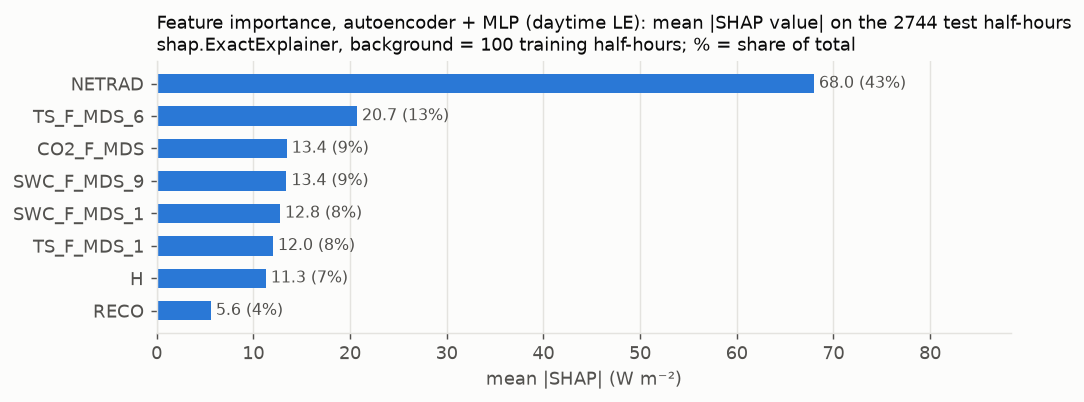

In [11]:
shap_values_day, shap_importance_day = shapley("daytime")
display(Image(FIG / "5_shap_importance_daytime.png"))